## Virtual reality — bout durations (2 wpf)

OMR in virtual reality for 2 wpf Danionella.

Plot example traces of fish fictive velocity (black) in response to forward visual motion for two target speeds (shown in grey).

Analyses bout durations in virtual-reality experiments at 2 wpf. 

Figures are saved to the project `figures/` directory and to `virtual_reality_experiments/media/`.

Import libraries:

In [2]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import VIRTUAL_REALITY_DIR, FIGURES_DIR, notebook_media_dir
path_behavior = str(VIRTUAL_REALITY_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("virtual_reality_experiments"))

%load_ext autoreload
%autoreload 2
from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
from functions.utilities import *

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr

plt.rcdefaults()
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Over different runs:

In [3]:
# path_behavior, path_media set in first cell

In [4]:
# path_media created in first cell

### Different gains:

In [5]:
widget()
experiments=[(path_behavior,'2024-01-04',12),
             (path_behavior,'2024-02-21',12),
             (path_behavior,'2024-05-21',12),
             (path_behavior,'2024-05-27',20),
             (path_behavior,'2024-06-05',3)
            ]

In [6]:
parameter_trials_str='alpha_trials'

In [24]:
#plot_trials_experiments_strength(experiments,parameter_trials_str,p0=5,ymax=7)#,ymin=0.01,log=1)

### Example trials:

In [8]:
e=0

path,date,run=experiments[e]

filenames=get_filenames(path,date,run)

with h5py.File(filenames['visual_flow'],'r') as f:
    exp=save_group_as_dict(f,'exp')
    prot_ps=save_group_as_dict(f,'prot_ps')
    cam_ps=save_group_as_dict(f,'cam_ps')
    proj_ps=save_group_as_dict(f,'proj_ps')


In [9]:
default()
inline()
plot_trials(exp,prot_ps,proj_ps)

interactive(children=(IntSlider(value=0, description='trial', max=13), Output()), _dom_classes=('widget-intera…

In [10]:
v_feedback_filt=get_v_feedback_filt(exp,proj_ps)
omega_feedback_filt=get_omega_feedback_filt(exp,proj_ps)
strength_filt=get_strengths_filt(exp,cam_ps)

In [11]:
theta_tail=np.zeros(len(exp['tail_points_list']))
for i in range(len(exp['tail_points_list'])):
    theta_tail[i]=np.rad2deg(np.arctan2(exp['tail_points_list'][i,-1,0],-exp['tail_points_list'][i,-1,1]))

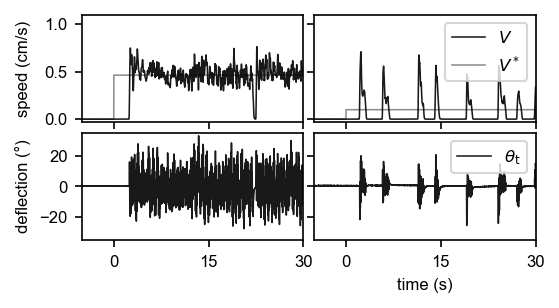

In [13]:
arial()
inline()
cf='k'
cc='gray'
fig=plt.figure(figsize=np.array([1,0.5])*0.6*textwidthSI,dpi=150)

trials=[4,6]

gs = fig.add_gridspec(2,len(trials), hspace=0.1, wspace=0.05)
axs = gs.subplots(sharex=True,sharey='row')

pausetimeplot=5
lw=0.75

for i in range(len(trials)):
    ax=axs[0,i]
    trial=trials[i]
    tmin=prot_ps['pause_start_times'][trial]
    thalf=prot_ps['flow_start_times'][trial]
    tmax=prot_ps['flow_start_times'][trial]+prot_ps['flow_duration_trials'][trial]
    cameratimes_trial=tuple([(exp['cameratimes']>thalf-pausetimeplot)&(exp['cameratimes']<tmax+pausetimeplot)])
    updatetimes_trial=tuple([(exp['updatetimes']>thalf-pausetimeplot)&(exp['updatetimes']<tmax+pausetimeplot)])

    ax.set_xlim(-pausetimeplot,prot_ps['flow_duration_trials'][trial]-5)
    

    ax.plot(exp['cameratimes'][cameratimes_trial]-exp['cameratimes'][cameratimes_trial][0]-pausetimeplot,strength_filt[cameratimes_trial]*strength_factor,c=cf,alpha=0.9,lw=lw,label='$V$')
    ax.plot(exp['updatetimes'][updatetimes_trial]-exp['updatetimes'][updatetimes_trial][0]-pausetimeplot,exp['v_flow'][updatetimes_trial]/exp['alpha'][updatetimes_trial]*strength_factor,lw=lw,c=cc,alpha=0.9,label=r'$V^*$',zorder=0)

    ax.set_ylim(-0.03,1.1)
    ax.set_yticks([0,0.5,1])
    ax.set_xticks([0,15,30])
    if i==0:
        ax.set_ylabel('speed (cm/s)')
    if i==len(trials)-1:
        ax.legend()
        ax.set_xlabel('time (s)')
        
        
    ax=axs[1,i]
    ax.plot(exp['cameratimes'][cameratimes_trial]-exp['cameratimes'][cameratimes_trial][0]-pausetimeplot,theta_tail[cameratimes_trial]-np.mean(theta_tail),c='k',alpha=0.9,lw=lw,label=r'$\theta_\mathrm{t}$')

    anglemax=35
    ax.set_ylim(-anglemax,anglemax)
    ax.set_yticks([-20,0,20])
    ax.set_xticks([0,15,30])
    if i==0:
        ax.set_ylabel(r'deflection (°)')
    if i==len(trials)-1:
        ax.legend()
        ax.set_xlabel('time (s)')

fig.align_ylabels()
plt.savefig(os.path.join(path_media,'Fig_5c_example_trials_transition_two_weeks.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_5c_example_trials_transition_two_weeks.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.show()

In [14]:
len(experiments)

5

In [15]:
for experiment in experiments:
    path,date,run=experiment

    filenames=get_filenames(path,date,run)

    with h5py.File(filenames['visual_flow'],'r') as f:
        exp=save_group_as_dict(f,'exp')
        prot_ps=save_group_as_dict(f,'prot_ps')
        cam_ps=save_group_as_dict(f,'cam_ps')
        
    print(prot_ps['protocol'],)

b'random_trials_different_alphas'
b'random_trials_different_alphas'
b'random_trials_different_alphas'
b'random_trials_different_alphas'
b'random_trials_different_alphas'


In [16]:
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

In [17]:
swimming_durations_list,params_list=get_swimming_durations_multiple_experiments(experiments,parameter_trials_str)

In [18]:
len(swimming_durations_list)

5

In [19]:
#this works only if all experiments have the same parameter values
params=params_list[0]
swimming_durations_pooled=[[] for j in range(len(params))]
for i in range(len(params_list)):
    for j in range(len(params_list[0])):
        swimming_durations_pooled[j]+=swimming_durations_list[i][j]

Duration weighted average:

In [20]:
swimming_durations_weighted_means=[[] for n in range(len(params_list))]
for n in range(len(params_list)):
    for i in range(len(params)):
        swimming_durations_weighted_means[n].append(np.average(swimming_durations_list[n][i],weights=swimming_durations_list[n][i]))

swimming_durations_weighted_means=np.array(swimming_durations_weighted_means)

In [21]:
swimming_durations_weighted_fish_median=np.median(swimming_durations_weighted_means,axis=0)
swimming_durations_weighted_fish_iqrp=np.quantile(swimming_durations_weighted_means,0.75,axis=0)-np.quantile(swimming_durations_weighted_means,0.5,axis=0)
swimming_durations_weighted_fish_iqrm=np.quantile(swimming_durations_weighted_means,0.5,axis=0)-np.quantile(swimming_durations_weighted_means,0.25,axis=0)

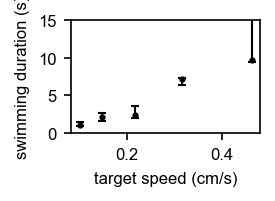

In [23]:
p0=2
capsize=2
ms=4
lw=1
fmt='.'

inline()
arial()

fig,ax=plt.subplots(figsize=np.array([1,0.6])*0.25*textwidthSI,dpi=150)

ax.errorbar(0.25/params[p0:]*strength_factor,swimming_durations_weighted_fish_median[p0:],[swimming_durations_weighted_fish_iqrm[p0:],swimming_durations_weighted_fish_iqrp[p0:]],fmt=fmt,ms=ms,lw=lw,capsize=capsize,c='k')


ax.set_ylim(0,15)
ax.set_xlabel(r'target speed (cm/s)')
ax.set_ylabel(r'swimming duration (s)')

plt.savefig(os.path.join(path_media,'Fig_5d_swimming_duration_two_weeks.pdf'),bbox_inches='tight',transparent=True,dpi=200)
plt.savefig(os.path.join(path_figures,'Fig_5d_swimming_duration_two_weeks.pdf'),bbox_inches='tight',transparent=True,dpi=200)

plt.show()